# Bound tests on real-world least-squares problems

This notebook runs the `MillerOpt` versus `RandomizedKaczmarz` comparison from `bound-is-not-tight-func.ipynb` on several real regression datasets: NASA wind-tunnel airfoil measurements, Delft full-scale yacht tests, and red/white Portuguese Vinho Verde wine chemistry measurements. UCI documents these problems at [Airfoil Self-Noise](https://archive.ics.uci.edu/dataset/291/airfoil%2Bself%2B), [Yacht Hydrodynamics](https://archive.ics.uci.edu/dataset/243/yacht%2Bhydrodynamics), and [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine%2Bquality).

Each loader returns `(name, A, b)`. Predictors are standardized and an intercept is added. The runner normalizes rows to match the current bound derivation; this makes the tested objective a row-weighted least-squares fit. It prints the condition number of the actual preprocessed matrix for each dataset.


In [22]:
from main import MillerOpt, RandomizedKaczmarz
import io
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data/uci-regression")


## Ready-to-use data loaders

Each loader downloads and caches its UCI archive under `data/uci-regression/`, then returns `(name, A, b)`. Predictors are standardized and an intercept is added. The runner normalizes rows to match the current bound assumptions and prints the condition number of the matrix it uses.


In [23]:
UCI_ARCHIVES = {
    "airfoil": "https://archive.ics.uci.edu/static/public/291/airfoil%2Bself%2Bnoise.zip",
    "yacht": "https://archive.ics.uci.edu/static/public/243/yacht%2Bhydrodynamics.zip",
    "wine": "https://archive.ics.uci.edu/static/public/186/wine%2Bquality.zip",
}


def _download_uci_archive(dataset_key):
    url = UCI_ARCHIVES[dataset_key]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive_path = DATA_DIR / f"{dataset_key}.zip"
    if not archive_path.exists():
        request = Request(
            url,
            headers={"User-Agent": "Mozilla/5.0 (compatible; least-squares-notebook/1.0)"},
        )
        try:
            with urlopen(request, timeout=30) as response:
                contents = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"Could not download the UCI {dataset_key} archive from {url}. "
                "Check network access or download the archive manually."
            ) from exc
        archive_path.write_bytes(contents)
    return zipfile.ZipFile(archive_path)


def _regression_problem(name, X, b):
    X = np.asarray(X, dtype=float)
    b = np.asarray(b, dtype=float).reshape(-1)
    if X.ndim != 2 or X.shape[0] != b.size:
        raise ValueError(f"Invalid regression data shapes: X={X.shape}, b={b.shape}")
    scale = X.std(axis=0)
    if np.any(scale == 0):
        raise ValueError(f"{name} has a constant predictor")
    X = (X - X.mean(axis=0)) / scale
    A = np.column_stack((np.ones(len(X)), X))
    return name, A, b


def airfoil_self_noise_loader():
    """NASA wind-tunnel airfoil measurements: predictors -> sound pressure."""
    with _download_uci_archive("airfoil") as archive:
        data_file = next(n for n in archive.namelist() if n.lower().endswith(".dat"))
        data = np.loadtxt(io.BytesIO(archive.read(data_file)))
    return _regression_problem("NASA Airfoil Self-Noise", data[:, :5], data[:, 5])


def yacht_hydrodynamics_loader():
    """Delft full-scale yacht tests: hull/velocity parameters -> resistance."""
    with _download_uci_archive("yacht") as archive:
        data_file = next(n for n in archive.namelist() if n.lower().endswith("yacht_hydrodynamics.data"))
        data = np.loadtxt(io.BytesIO(archive.read(data_file)))
    return _regression_problem("Delft Yacht Hydrodynamics", data[:, :6], data[:, 6])


def wine_quality_loader(color="red"):
    """Portuguese Vinho Verde chemistry measurements -> sensory quality score."""
    color = color.lower()
    if color not in {"red", "white"}:
        raise ValueError("color must be 'red' or 'white'")
    with _download_uci_archive("wine") as archive:
        data_file = next(n for n in archive.namelist()
                         if n.lower().endswith(f"winequality-{color}.csv"))
        data = np.genfromtxt(io.BytesIO(archive.read(data_file)), delimiter=";", skip_header=1)
    return _regression_problem(f"UCI Wine Quality ({color})", data[:, :-1], data[:, -1])


dataset_loaders = {
    "airfoil": airfoil_self_noise_loader,
    "yacht": yacht_hydrodynamics_loader,
    "wine_red": lambda: wine_quality_loader("red"),
    "wine_white": lambda: wine_quality_loader("white"),
}


In [27]:
def run_dataset_test(
    dataloader,
    *,
    prop_noised=0.1,
    rhs_noise_fraction=0.05,
    teacher_noise_scale=0.1,
    x0_noise_scale=1.0,
    iters=3000,
    seed=1,
    make_plot=True,
):
    """Run the bound comparison on `(name, A, b)` returned by dataloader().

    The least-squares solution to the supplied data is the reference x_sol.
    """
    name, A, b = dataloader()
    A = np.asarray(A, dtype=float).copy()
    b = np.asarray(b, dtype=float).reshape(-1).copy()
    if A.ndim != 2 or A.shape[0] != b.size:
        raise ValueError(f"Expected A (m,d) and b (m,), got {A.shape} and {b.shape}")

    # Empty equations carry no information. Normalize nonzero rows as assumed by the bounds.
    row_norms = np.linalg.norm(A, axis=1)
    keep = row_norms > 0
    A, b, row_norms = A[keep], b[keep], row_norms[keep]
    A, b = A / row_norms[:, None], b / row_norms
    n, d = A.shape
    if n <= d:
        raise ValueError(f"Need an overdetermined system; got A with shape {A.shape}")

    rng = np.random.default_rng(seed)
    x_sol = np.linalg.lstsq(A, b, rcond=None)[0]
    noised_count = max(1, int(n * prop_noised)) if prop_noised > 0 else 0
    noised_indices = rng.choice(n, size=noised_count, replace=False)
    b_test = b.copy()
    rhs_scale = np.sqrt(np.mean(b**2))
    b_test[noised_indices] += rng.normal(
        scale=rhs_noise_fraction * max(rhs_scale, 1e-12), size=noised_count
    )
    teacher_scale = teacher_noise_scale * max(np.linalg.norm(x_sol) / np.sqrt(d), 1.0)
    x_teacher = x_sol + rng.normal(scale=teacher_scale, size=d)
    x0 = x_sol + rng.normal(scale=x0_noise_scale, size=d)

    shared = dict(x0=x0, A=A, b=b_test, x_sol=x_sol, batch_size=n, maxiter=iters, seed=seed)
    guided = MillerOpt(**shared, teacher=x_teacher, noised_indices=noised_indices)
    random = RandomizedKaczmarz(**shared)
    for solver in (guided, random):
        solver.solve()
    if not np.isclose(guided.parameter_errors[0], random.parameter_errors[0], rtol=1e-12, atol=1e-12):
        raise RuntimeError("Both solvers should start from the same x0 and x_sol")

    condition_number = np.linalg.cond(A)
    print(f"{name}: A={A.shape}, nnz={np.count_nonzero(A)}, rank={np.linalg.matrix_rank(A)}")
    print(f"  condition number after preprocessing: {condition_number:.3e}")
    print(f"  initial LS residual norm: {np.linalg.norm(A @ x_sol - b):.3e}")
    print(f"  alpha={guided.alpha:.3e}, beta={guided.beta:.3e}, gamma={guided.gamma:.3e}")
    print(f"  Peter-Paul bound floor={guided.diagnostics['bound_peter_paul_floor']:.3e}; time-bound floor={guided.diagnostics['bound_diff_eq_floor']:.3e}")

    if make_plot:
        fig, ax = plt.subplots(figsize=(9, 5))
        iteration_range = np.arange(iters)
        e0 = guided.parameter_errors[0]

        # Same two theoretical curves used in bound-is-not-tight-func.ipynb.
        bound_peter_paul_floor = guided.diagnostics["bound_peter_paul_floor"]
        bound_peter_paul = (1 - guided.alpha / 2) ** iteration_range * (e0 - bound_peter_paul_floor) + bound_peter_paul_floor
        ax.plot(iteration_range, bound_peter_paul, color="tab:red", lw=1.5, label="Bound (PP)")
        ax.axhline(bound_peter_paul_floor, color="tab:red", ls="--", label="Floor (PP)")

        # The first component is the predicted number of iterations to reach
        # the current error; plot it as the iteration coordinate.
        bound_diff_eq = np.asarray(guided.diagnostics["bound_diff_eq"], dtype=float)
        valid = np.isfinite(bound_diff_eq).all(axis=1)
        ax.plot(bound_diff_eq[valid, 0], bound_diff_eq[valid, 1], color="tab:green", lw=1.5,
                label="Bound (DE)")
        ax.axhline(guided.diagnostics["bound_diff_eq_floor"], color="tab:green", ls="--",
                   label="Floor (DE)")

        ax.plot(guided.parameter_errors, color="black", lw=3, label="TeacherOpt parameter error")
        ax.plot(random.parameter_errors, color="gray", lw=2, label="Randomized Kaczmarz parameter error")
        ax.scatter([0], [e0], color="black", marker="o", zorder=5, label="Shared x0 error")
        ax.set(title=f"{name}: solver errors and bounds", xlabel="Iteration", ylabel="Squared parameter error")
        ax.legend()
        fig.tight_layout()

        
        ax.set_xscale("log")
        # ax.set_yscale("log")
        plt.show()

    return {"name": name, "A": A, "b": b_test, "x_sol": x_sol,
            "miller": guided, "randomized": random}


## Choose a dataset and run the comparison

Pick any key in `dataset_loaders`. Each run reports the preprocessed design matrix condition number before plotting the solver errors and bounds. The UCI pages document the underlying real-world problems: [Airfoil Self-Noise](https://archive.ics.uci.edu/dataset/291/airfoil%2Bself%2B), [Yacht Hydrodynamics](https://archive.ics.uci.edu/dataset/243/yacht%2Bhydrodynamics), and [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine%2Bquality).

The OG curve uses the same geometric envelope and floor as `bound-is-not-tight-func.ipynb`. The differential-equation curve stores `(predicted iterations, error)`, so its first coordinate is plotted as iterations. Both envelopes approach their respective horizontal floors; they need not reach them in a finite run.

NASA Airfoil Self-Noise: A=(1503, 6), nnz=9018, rank=6
  condition number after preprocessing: 3.583e+00
  initial LS residual norm: 8.385e+01
  alpha=2.356e-02, beta=2.185e+01, gamma=1.161e+02
  Miller bound floor=1.729e+06; time-bound floor=8.695e+05


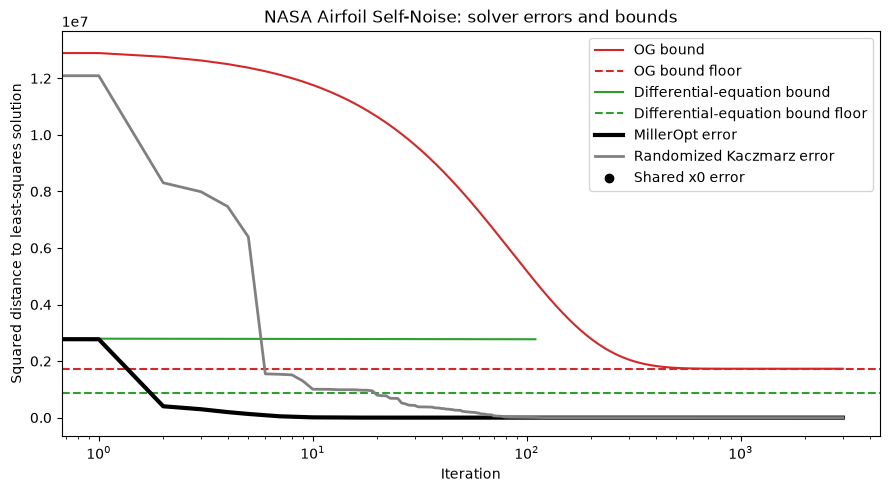

In [28]:
# Options: "airfoil", "yacht", "wine_red", "wine_white"
selected_dataset = "airfoil"
result = run_dataset_test(dataset_loaders[selected_dataset], iters=3000, seed=1)

# To run all loaders (takes longer):
# results = {
#     name: run_dataset_test(loader, iters=3000, seed=1)
#     for name, loader in dataset_loaders.items()
# }


## Plug in another dataset

Pass any zero-argument loader returning `(name, A, b)`. The runner expects a dense, overdetermined real system and keeps `A` in memory. For a streaming source, materialize or concatenate its rows first because the current solvers need the full matrix for residual and singular-value calculations.